# L1, L2 and Elastic Net Regularization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
X, y, true_coef = make_regression(n_samples=2000, n_features=30, n_informative=8,
                                  noise=25, coef=True, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

ridge_alpha = 10
lasso_alpha = 1
enet_alpha = 0.1
enet_l1_ratio = 0.5

In [3]:
def evaluate(model):
    model.fit(X_train, y_train)
    return dict(
        Train_R2=r2_score(y_train, model.predict(X_train)),
        Test_R2=r2_score(y_test, model.predict(X_test)),
        Test_MSE=mean_squared_error(y_test, model.predict(X_test)),
        Zero_Coefficients=int(np.sum(np.abs(model.coef_) < 1e-6)),
    )

In [4]:
models = {
    "No Regularization": LinearRegression(),
    "L2 (Ridge)": Ridge(alpha=ridge_alpha),
    "L1 (Lasso)": Lasso(alpha=lasso_alpha),
    "Elastic Net": ElasticNet(alpha=enet_alpha, l1_ratio=enet_l1_ratio),
}
results = pd.DataFrame({name: evaluate(m) for name, m in models.items()}).T

In [5]:
print(results.round(4).to_string())

                   Train_R2  Test_R2  Test_MSE  Zero_Coefficients
No Regularization    0.9654   0.9715  608.7544                0.0
L2 (Ridge)           0.9654   0.9713  612.5622                0.0
L1 (Lasso)           0.9645   0.9709  620.5647               17.0
Elastic Net          0.9628   0.9679  684.4403                1.0


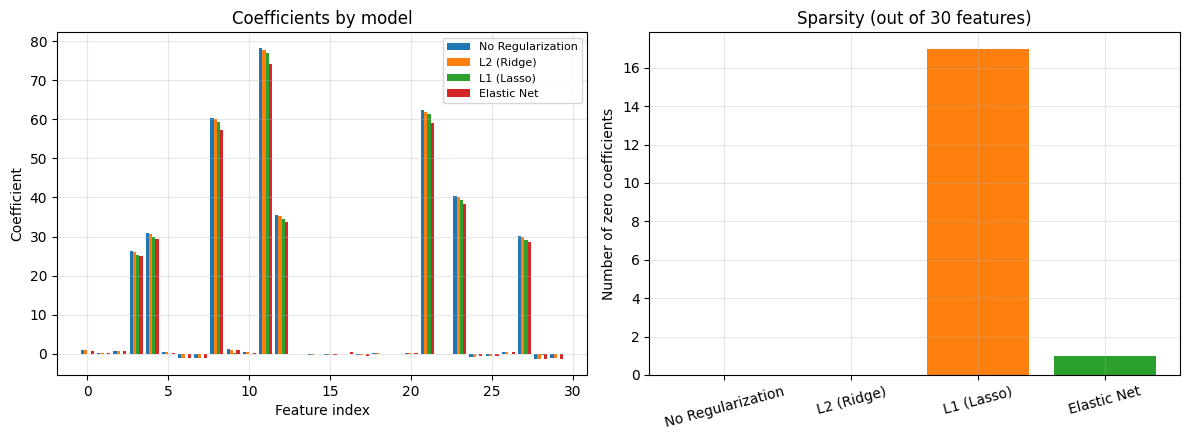

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

idx = np.arange(30)
for k, (name, m) in enumerate(models.items()):
    ax[0].bar(idx + (k - 1.5) * 0.2, m.coef_, width=0.2, label=name)
ax[0].set_xlabel("Feature index")
ax[0].set_ylabel("Coefficient")
ax[0].set_title("Coefficients by model")
ax[0].legend(fontsize=8)

ax[1].bar(results.index, results["Zero_Coefficients"], color=["gray", "tab:blue", "tab:orange", "tab:green"])
ax[1].set_ylabel("Number of zero coefficients")
ax[1].set_title("Sparsity (out of 30 features)")
ax[1].tick_params(axis="x", rotation=15)

for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
settings = [
    ("Ridge alpha", "10", "1000", "L2 (Ridge)", Ridge(alpha=1000)),
    ("Lasso alpha", "1", "20", "L1 (Lasso)", Lasso(alpha=20)),
    ("Elastic Net alpha", "0.1", "5", "Elastic Net", ElasticNet(alpha=5, l1_ratio=enet_l1_ratio)),
    ("Elastic Net l1_ratio", "0.5", "0.9", "Elastic Net", ElasticNet(alpha=enet_alpha, l1_ratio=0.9)),
]
rows = []
for name, old, new, key, model in settings:
    r = evaluate(model)
    o = results.loc[key]
    rows.append([name, old, new, f"{o.Test_MSE:.2f} / {int(o.Zero_Coefficients)}", f"{r['Test_MSE']:.2f} / {r['Zero_Coefficients']}"])
table = pd.DataFrame(rows, columns=["Parameter", "Original", "Modified", "Original (Test MSE / zero coef.)", "Modified (Test MSE / zero coef.)"])
table

,Parameter,Original,Modified,Original (Test MSE / zero coef.),Modified (Test MSE / zero coef.)
0,Ridge alpha,10,1000,612.56 / 0,4368.35 / 0
1,Lasso alpha,1,20,620.56 / 17,4453.40 / 22
2,Elastic Net alpha,0.1,5,684.44 / 1,12104.79 / 18
3,Elastic Net l1_ratio,0.5,0.9,684.44 / 1,615.32 / 2
